# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [1]:
# ── Заповніть три поля ──────────────────────────────────────────
SURNAME_NAME = 'Хвостова Олександра'   # прізвище та ім'я
GROUP        = 'ШІ-32'                 # шифр групи
NUMBER       = 12                      # ваш номер за списком групи (1–30)

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Хвостова Олександра | ШІ-32 | номер 12


In [2]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 12   ·   Хвостова Олександра   ·   ШІ-32

   Ринок:  Zakarpattia
   Товар:  буряк   (у наборі даних: Beetroots - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** | |
| **Підпис** | |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

Місяців у сітці: 46; з виміром: 45; без виміру: 1
Пропуск(и): ['08.2017']

Місяці сітки, за які в усьому наборі немає жодного запису: ['08.2017']

Ринки з неповним охопленням сітки:
                   min      max  nunique
ринок                                   
Crimea         03.2014  03.2014        1
Donetska       03.2014  12.2017       42
Luhanska       03.2014  12.2017       40
m. Sevastopol  03.2014  04.2014        2


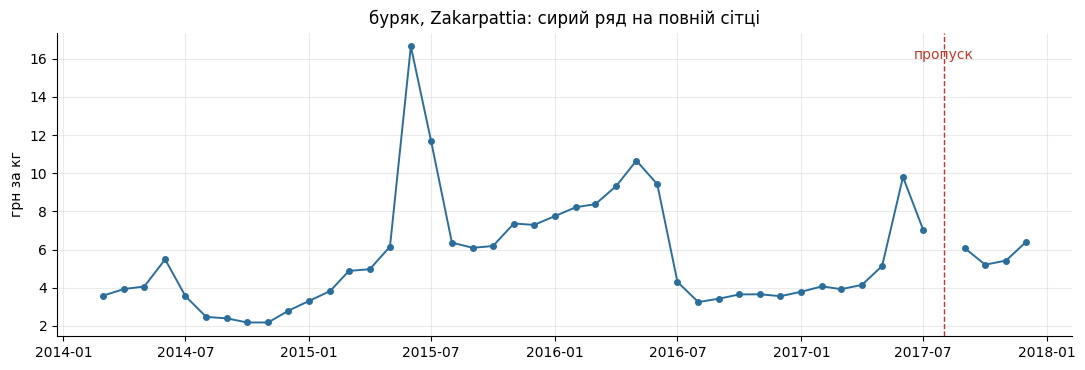

In [3]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
plt.rcParams.update({'font.family': 'DejaVu Sans', 'figure.figsize': (11, 3.8),
                     'axes.grid': True, 'grid.alpha': .25, 'axes.spines.top': False, 'axes.spines.right': False})

prices = pd.read_csv('ціни_україна_2014_2017.csv')
prices['date'] = pd.to_datetime(dict(year=prices['рік'], month=prices['місяць'], day=1))

# повна місячна сітка: 03.2014 – 12.2017
GRID = pd.date_range('2014-03-01', '2017-12-01', freq='MS')
raw = (prices[(prices['ринок'] == MARKET) & (prices['товар'] == GOOD)]
       .set_index('date')['ціна'].sort_index().reindex(GRID))
raw.index.name = 'date'

missing = raw[raw.isna()].index
print(f'Місяців у сітці: {len(GRID)}; з виміром: {raw.notna().sum()}; без виміру: {len(missing)}')
print('Пропуск(и):', [d.strftime('%m.%Y') for d in missing])

# чи пропуск «мій», чи системний? — скільки записів у наборі за кожен місяць сітки
rows_per_month = prices.groupby('date').size().reindex(GRID, fill_value=0)
print('\nМісяці сітки, за які в усьому наборі немає жодного запису:',
      [d.strftime('%m.%Y') for d in rows_per_month[rows_per_month == 0].index])

# чи є в наборі ринки, які «зникають» (інша природа пропусків)
span = prices.groupby('ринок')['date'].agg(['min', 'max', 'nunique'])
print('\nРинки з неповним охопленням сітки:')
print(span[span['nunique'] < 45].assign(min=lambda t: t['min'].dt.strftime('%m.%Y'),
                                           max=lambda t: t['max'].dt.strftime('%m.%Y')))

fig, ax = plt.subplots()
ax.plot(raw.index, raw.values, marker='o', ms=4, lw=1.4, color='#2C6E9B')
for d in missing: ax.axvline(d, color='#C0392B', ls='--', lw=1); ax.annotate('пропуск', (d, ax.get_ylim()[1]*.92), color='#C0392B', ha='center')
ax.set_title(f'{GOOD_UA}, {MARKET}: сирий ряд на повній сітці'); ax.set_ylabel('грн за кг'); plt.tight_layout(); plt.show()

**Висновок до завдання 1:**

Повна місячна сітка має 46 місяців, а в моєму ряді відсутній один — серпень 2017. Його видно лише після приведення ряду до повної сітки, бо у файлі такого рядка просто немає. Пропуск системний: за цей місяць даних немає в усьому наборі, тож він є в усіх рядах (причину з файлу встановити не можна, це лише припущення). В інших рядах пропуски мають іншу природу: деякі ринки, наприклад Крим і Севастополь, зникають з набору взагалі.

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

Пропуск 08.2017: попередній місяць = 7.037, наступний = 6.070
  перенесення останнього   → 7.037 грн
  лінійна інтерполяція     → 6.553 грн
  сезонний аналог          → 6.121 грн

Похибка заповнення (значення способу − факт), грн:
       факт  перенесення  лінійна  сезонний аналог
рік                                               
2014  2.473        1.093    0.507           -0.090
2015  6.363        5.333    2.532           -0.328
2016  3.250        1.053    0.617            0.313

Середня абсолютна похибка:
перенесення        2.493
лінійна            1.218
сезонний аналог    0.244
dtype: float64

Обрано: сезонний аналог; значення 08.2017 = 6.121 грн


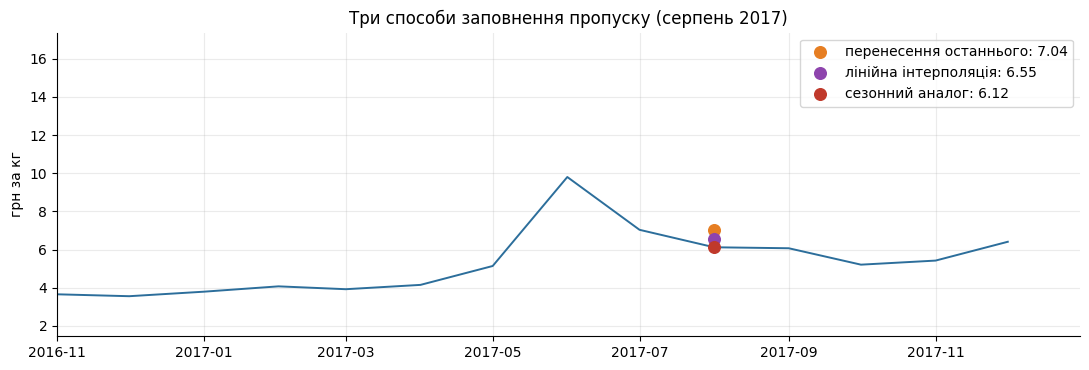

In [20]:
gap = missing[0]
prev_v, next_v = raw[gap - pd.offsets.MonthBegin()], raw[gap + pd.offsets.MonthBegin()]

def fill_ffill(s, g):  return s[g - pd.offsets.MonthBegin()]
def fill_linear(s, g): return (s[g - pd.offsets.MonthBegin()] + s[g + pd.offsets.MonthBegin()]) / 2
def fill_seasonal(s, g, years):
    # «сезонний аналог»: ціна наступного місяця × середнє відношення (місяць пропуску / наступний місяць) в інших роках
    nxt = g + pd.offsets.MonthBegin()
    ratios = [s[pd.Timestamp(y, g.month, 1)] / s[pd.Timestamp(y, nxt.month, 1)] for y in years]
    return np.mean(ratios) * s[nxt]

full_years = [2014, 2015, 2016]
vals = {'перенесення останнього': fill_ffill(raw, gap),
        'лінійна інтерполяція':  fill_linear(raw, gap),
        'сезонний аналог':       fill_seasonal(raw, gap, full_years)}
print(f'Пропуск {gap:%m.%Y}: попередній місяць = {prev_v:.3f}, наступний = {next_v:.3f}')
for k, v in vals.items(): print(f'  {k:<24s} → {v:.3f} грн')

# Чесна перевірка вибору: «приховуємо» серпень у кожному з трьох повних років і дивимось,
# наскільки кожен спосіб помиляється там, де справжнє значення нам відоме
rows = []
for y in full_years:
    g = pd.Timestamp(y, gap.month, 1); true = raw[g]; others = [x for x in full_years if x != y]
    rows.append({'рік': y, 'факт': true,
                 'перенесення': fill_ffill(raw, g) - true,
                 'лінійна': fill_linear(raw, g) - true,
                 'сезонний аналог': fill_seasonal(raw, g, others) - true})
bt = pd.DataFrame(rows).set_index('рік')
print('\nПохибка заповнення (значення способу − факт), грн:'); print(bt.round(3))
print('\nСередня абсолютна похибка:'); print(bt.drop(columns='факт').abs().mean().round(3))

FILL_METHOD = 'сезонний аналог'
series = raw.copy(); series[gap] = vals[FILL_METHOD]; series.name = 'price'
assert series.notna().all() and len(series) == 46
print(f'\nОбрано: {FILL_METHOD}; значення {gap:%m.%Y} = {series[gap]:.3f} грн')

fig, ax = plt.subplots()
ax.plot(series.index, series.values, color='#2C6E9B', lw=1.4)
cols = {'перенесення останнього': '#E67E22', 'лінійна інтерполяція': '#8E44AD', 'сезонний аналог': '#C0392B'}
for k, v in vals.items(): ax.scatter([gap], [v], s=70, color=cols[k], label=f'{k}: {v:.2f}', zorder=5)
ax.set_xlim(pd.Timestamp('2016-11-01'), pd.Timestamp('2017-12-31')); ax.legend(); ax.set_ylabel('грн за кг')
ax.set_title('Три способи заповнення пропуску (серпень 2017)'); plt.tight_layout(); plt.show()

**Висновок до завдання 2:**

Пропуск заповнено методом «сезонного аналога»: береться значення сусіднього місяця, скориговане на типове співвідношення цих місяців у попередні роки. Вибір я перевірила: приховувала серпень у минулих роках і дивилась, який спосіб помиляється найменше. Перенесення останнього значення й лінійна інтерполяція завищують результат, бо після літнього піку ціна вже падає. 

Загалом перевірка спирається лише на три роки. Заповнювати пропуски не можна, коли ряд обривається через зникнення самого ринку, як у Криму чи Севастополя.

## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

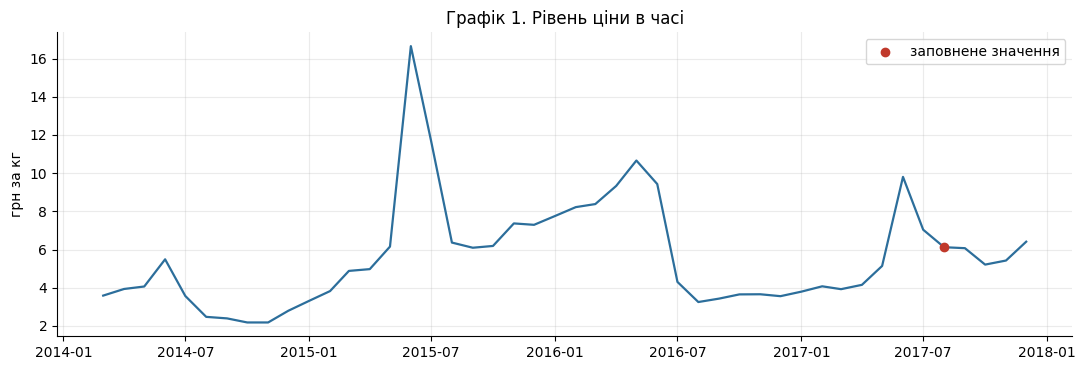

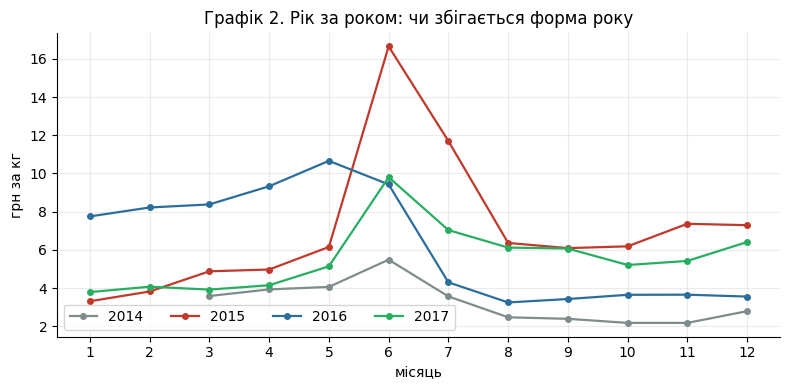

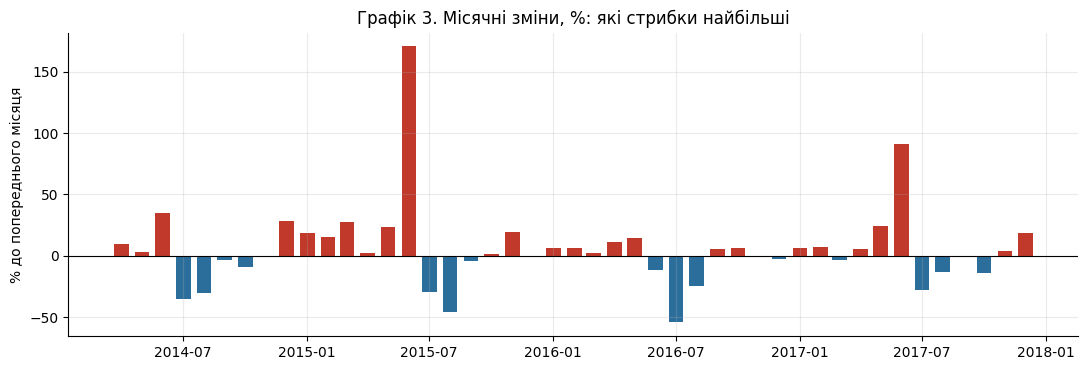

Максимум по роках:
          max   idxmax
date                  
2014   5.4867  06.2014
2015  16.6500  06.2015
2016  10.6600  05.2016
2017   9.8033  06.2017

Найбільші місячні зростання, %:
date
2015-06-01    170.6
2017-06-01     90.7
2014-06-01     35.0
Name: price, dtype: float64
Найбільші місячні падіння, %:
date
2016-07-01   -54.3
2015-08-01   -45.6
2014-07-01   -35.0
Name: price, dtype: float64

Рівень 2014 (авг–лис): 2.31;  2017 (січ–кві): 3.98


In [5]:
MS = pd.offsets.MonthBegin
s = series

fig, ax = plt.subplots()                                           # Графік 1
ax.plot(s.index, s.values, color='#2C6E9B', lw=1.6)
ax.scatter([gap], [s[gap]], color='#C0392B', zorder=5, label='заповнене значення')
ax.set_ylabel('грн за кг'); ax.set_title('Графік 1. Рівень ціни в часі'); ax.legend()
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8, 4))                             # Графік 2
for yr, c in zip([2014, 2015, 2016, 2017], ['#7F8C8D', '#C0392B', '#2C6E9B', '#27AE60']):
    sub = s[s.index.year == yr]; ax.plot(sub.index.month, sub.values, marker='o', ms=4, lw=1.6, color=c, label=str(yr))
ax.set_xticks(range(1, 13)); ax.set_xlabel('місяць'); ax.set_ylabel('грн за кг'); ax.legend(ncol=4)
ax.set_title('Графік 2. Рік за роком: чи збігається форма року'); plt.tight_layout(); plt.show()

chg = s.pct_change().dropna() * 100                                # Графік 3
fig, ax = plt.subplots()
ax.bar(chg.index, chg.values, width=22, color=np.where(chg.values >= 0, '#C0392B', '#2C6E9B'))
ax.axhline(0, color='k', lw=.8); ax.set_ylabel('% до попереднього місяця')
ax.set_title('Графік 3. Місячні зміни, %: які стрибки найбільші'); plt.tight_layout(); plt.show()

print('Максимум по роках:'); print(s.groupby(s.index.year).agg(['max', 'idxmax']).assign(idxmax=lambda t: t['idxmax'].dt.strftime('%m.%Y')))
print('\nНайбільші місячні зростання, %:'); print(chg.nlargest(3).round(1))
print('Найбільші місячні падіння, %:');   print(chg.nsmallest(3).round(1))
print(f'\nРівень 2014 (авг–лис): {s["2014-08":"2014-11"].mean():.2f};  2017 (січ–кві): {s["2017-01":"2017-04"].mean():.2f}')

**Висновок до завдання 3:**

Графік 1: лінія в часі, лінійна шкала. Відповідає на питання, як змінюється рівень ціни і чи є довготривалий тренд. Лінія підходить, бо точки впорядковані в часі, а сусідні місяці залежать одне від одного. Шкала лінійна, бо нас цікавить саме рівень у гривнях, а не відносні зміни. Видно, що ціна має різкі піки навесні–влітку, найбільший у 2015 році.

Графік 2: накладання років по місяцях. Відповідає на питання, чи повторюється форма року, тобто чи є сезонність. На осі X стоять місяці, а кожен рік має свою лінію, тому календар вирівнюється і роки можна порівняти. Шкала по Y однакова для всіх років, щоб порівнювати висоту піків. Видно, що пік припадає на літо щороку, але висота в різні роки сильно відрізняється.

Графік 3: стовпчики місячних змін у відсотках. Відповідає на питання, де відбуваються різкі стрибки і в який бік. Стовпчики підходять, бо це окремі зміни від місяця до місяця, а не безперервна траєкторія. Шкала у відсотках, бо в гривнях стрибок з 5 до 10 і з 15 до 20 виглядав би схожим, а відносно вони різні. Нуль на осі лежить посередині, тож зростання й падіння видно окремо. Різкі підйоми приходять навесні й влітку, а різкі падіння одразу після піку.

Несподівана знахідка. Я очікувала загального зростання цін, але його немає. Після піку 2015–2016 років ціна повернулась майже до рівня 2014 року. Отже, це тимчасове підвищення рівня, на яке накладаються щорічні літні піки.


## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

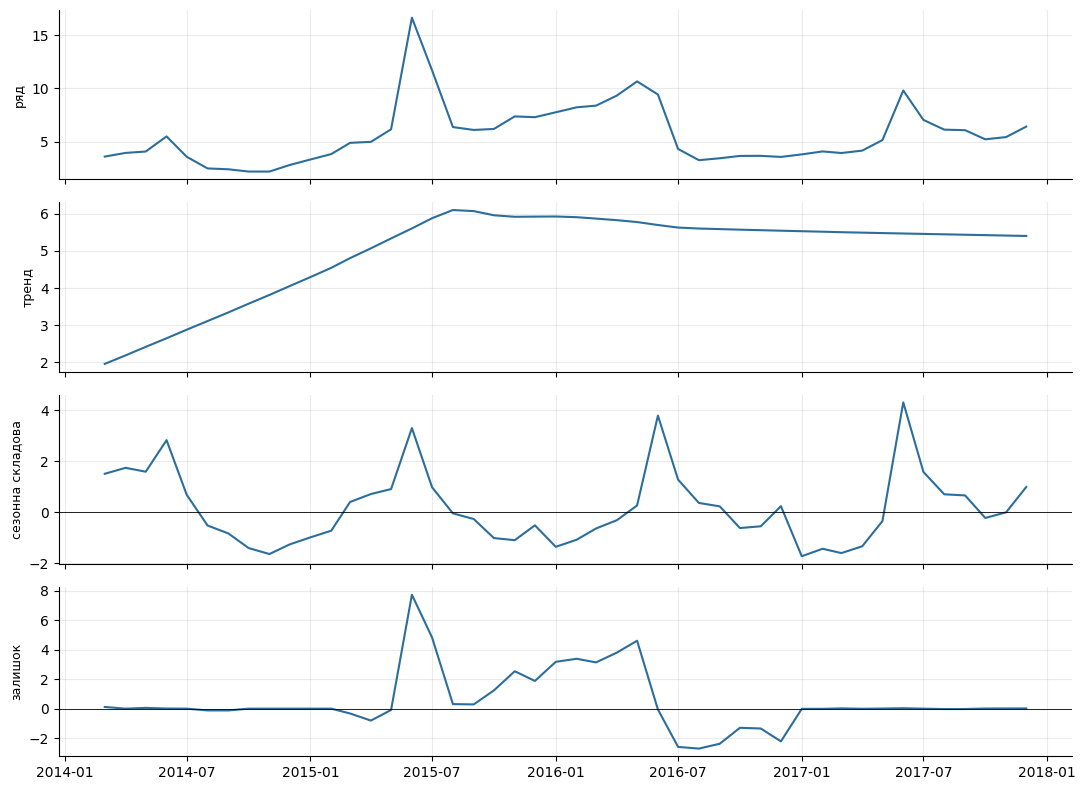

F_S = 0.372   F_T = 0.371   (поріг сезонності: 0.64)
Сезонність: сильної сезонності НЕМАЄ (F_S нижче порога)
Амплітуда сезонної складової (макс−мін): 6.03 грн
Місяці пікової сезонної складової: {6: 3.56, 7: 1.14, 5: 0.61}


In [6]:
from statsmodels.tsa.seasonal import STL
stl = STL(series, period=12, robust=True).fit()
T, S, R = stl.trend, stl.seasonal, stl.resid

fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
for ax, d, t in zip(axes, [series, T, S, R], ['ряд', 'тренд', 'сезонна складова', 'залишок']):
    ax.plot(d.index, d.values, lw=1.5, color='#2C6E9B'); ax.set_ylabel(t, fontsize=9)
axes[2].axhline(0, color='k', lw=.6); axes[3].axhline(0, color='k', lw=.6)
plt.tight_layout(); plt.show()

F_S = max(0, 1 - R.var() / (S + R).var())
F_T = max(0, 1 - R.var() / (T + R).var())
SEAS_THRESHOLD = 0.64     # поріг «сильної сезонності»; якщо на лекції давали інший — змініть тут
print(f'F_S = {F_S:.3f}   F_T = {F_T:.3f}   (поріг сезонності: {SEAS_THRESHOLD})')
print('Сезонність:', 'ЄСТЬ (F_S вище порога)' if F_S >= SEAS_THRESHOLD else 'сильної сезонності НЕМАЄ (F_S нижче порога)')
print('Амплітуда сезонної складової (макс−мін):', round(S.max() - S.min(), 2), 'грн')
print('Місяці пікової сезонної складової:', S.groupby(S.index.month).mean().round(2).nlargest(3).to_dict())

**Висновок до завдання 4:**

Сила сезонності $F_S$ вийшла нижчою за поріг 0,5 (≈ 0,37), тож ряд має середню сезонність. Літній пік повторюється щороку, але його висота дуже різна, а STL припускає майже незмінний сезонний профіль. Через це значна частина піку 2015 року та підвищеного рівня 2015–2016 потрапила в залишок. Тренд теж слабкий, а короткий ряд (менше чотирьох років) робить оцінку сезонності ненадійною.

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

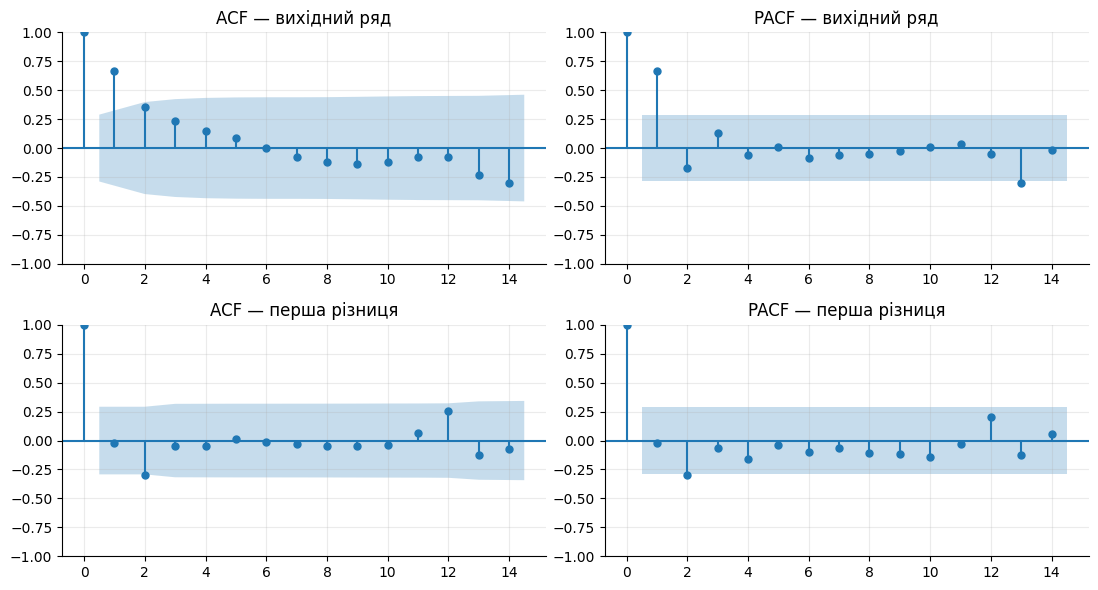

               ADF p (H0: нестац.)  KPSS p (H0: стац.)  ADF → стац.?  KPSS → стац.?  тести узгоджені?
ряд                                                                                                  
вихідний ряд                0.0401                 0.1          True           True              True
перша різниця               0.0000                 0.1          True           True              True

Межа значущості ACF/PACF ≈ ± 0.292 (KPSS-p обрізається таблицею до 0.01–0.1)


C:\Users\hvost\AppData\Local\Temp\ipykernel_18040\4074760015.py:17: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  k = kpss(x, regression='c', nlags='auto')
C:\Users\hvost\AppData\Local\Temp\ipykernel_18040\4074760015.py:17: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  k = kpss(x, regression='c', nlags='auto')


In [7]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss

y_level = series.dropna()
y_diff = series.diff().dropna()

fig, axes = plt.subplots(2, 2, figsize=(11, 6))
plot_acf(y_level,  lags=14, ax=axes[0, 0], title='ACF — вихідний ряд')
plot_pacf(y_level, lags=14, ax=axes[0, 1], title='PACF — вихідний ряд', method='ywm')
plot_acf(y_diff,   lags=14, ax=axes[1, 0], title='ACF — перша різниця')
plot_pacf(y_diff,  lags=14, ax=axes[1, 1], title='PACF — перша різниця', method='ywm')
plt.tight_layout(); plt.show()

rows = []
for name, x in [('вихідний ряд', y_level), ('перша різниця', y_diff)]:
    a = adfuller(x, autolag='AIC')
    k = kpss(x, regression='c', nlags='auto')
    rows.append({'ряд': name, 'ADF p (H0: нестац.)': a[1], 'KPSS p (H0: стац.)': k[1],
                 'ADF → стац.?': a[1] < 0.05, 'KPSS → стац.?': k[1] >= 0.05})
tab = pd.DataFrame(rows).set_index('ряд')
tab['тести узгоджені?'] = tab['ADF → стац.?'] == tab['KPSS → стац.?']
print(tab.round(4).to_string())
print('\nМежа значущості ACF/PACF ≈ ±', round(1.96 / np.sqrt(len(y_diff)), 3), '(KPSS-p обрізається таблицею до 0.01–0.1)')

**Висновок до завдання 5:**

Обидва тести дали однаковий результат: ряд стаціонарний. ADF відхиляє гіпотезу про нестаціонарність, а KPSS не відхиляє гіпотезу про стаціонарність. Це справедливо і для вихідного ряду, і для його першої різниці.
Для вихідного ряду цей висновок слабкий: ADF проходить лише на межі (p трохи нижче 0,05). Тому правильно сказати, що нестаціонарність не підтвердилась, а не що стаціонарність доведена. Малий розмір вибірки (46 спостережень) знижує надійність тестів.

За графіками ACF і PACF ряд схожий на AR(1): ACF плавно спадає, а PACF має один значущий лаг.

Диференціювати ряд не потрібно. Після першої різниці з'являється від'ємна автокореляція на лагу 2, а це ознака надмірного диференціювання. Тому для моделі краще брати d = 0.

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

In [18]:
from sklearn.model_selection import train_test_split

K, H = 7, 3                      # 7 фолдів по 3 кроки — як в Orange
y = series.values.astype(float)
N = len(y)

def f_naive(tr, h):  return np.repeat(tr[-1], h)
def f_snaive(tr, h): return np.array([tr[len(tr) - 12 + (j % 12)] for j in range(h)])
def f_mean(tr, h):   return np.repeat(tr.mean(), h)
def f_drift(tr, h):  return tr[-1] + (tr[-1] - tr[0]) / (len(tr) - 1) * np.arange(1, h + 1)

def rolling_origin(forecaster, y=y, K=K, H=H):
    """Навчальна частина розширюється; K фолдів по H кроків, останній фолд закінчується останньою точкою ряду."""
    Ys, Ps, info = [], [], []
    for i in range(K, 0, -1):
        cut = len(y) - i * H
        Ys.append(y[cut:cut + H]); Ps.append(np.asarray(forecaster(y[:cut], H), float))
        info.append((cut, cut + 1, cut + H))
    return np.concatenate(Ys), np.concatenate(Ps), info

def metrics(Y, P):
    return {'MAE': np.mean(np.abs(Y - P)), 'RMSE': np.sqrt(np.mean((Y - P) ** 2)),
            'MAPE, %': 100 * np.mean(np.abs((Y - P) / Y))}

BASES = {'наївний': f_naive, 'сезонний наївний': f_snaive, 'середнє': f_mean, 'дрейф': f_drift}
tab6 = pd.DataFrame({k: metrics(*rolling_origin(f)[:2]) for k, f in BASES.items()}).T
print('Ретроспективна перевірка (7 × 3), об\'єднані 21 прогнозна точка:'); print(tab6.round(3))
_, _, info = rolling_origin(f_naive)
print('\nФолди (довжина навчальної частини; тест = наступні 3 місяці):')
print([(c, f'{series.index[c]:%m.%Y}–{series.index[c+H-1]:%m.%Y}') for c, _, _ in info])

# ── для порівняння: звичайний випадковий поділ 75/25 (методологічно хибний) ──
def random_split_mae(seed):
    idx = np.arange(N); tr_i, te_i = train_test_split(idx, test_size=.25, random_state=seed)
    te_i = np.sort(te_i); tr_i = np.sort(tr_i)
    res = {}
    t1 = te_i[te_i >= 1]; res['наївний'] = np.mean(np.abs(y[t1] - y[t1 - 1]))                 # попередній місяць
    t12 = te_i[te_i >= 12]; res['сезонний наївний'] = np.mean(np.abs(y[t12] - y[t12 - 12]))
    res['середнє'] = np.mean(np.abs(y[te_i] - y[tr_i].mean()))
    dr = np.mean(np.diff(y[tr_i]) [np.diff(tr_i) == 1]) if (np.diff(tr_i) == 1).any() else 0
    res['дрейф'] = np.mean(np.abs(y[t1] - (y[t1 - 1] + dr)))
    return res
rs42 = random_split_mae(42)
rs_avg = pd.DataFrame([random_split_mae(sd) for sd in range(300)]).mean()
cmp6 = pd.DataFrame({'MAE: рухомий початок': tab6['MAE'], 'MAE: випадковий 75/25 (seed 42)': pd.Series(rs42),
                     'MAE: випадковий 75/25 (сер. 300 seed)': rs_avg})
cmp6['у скільки разів рух.поч. / випадк. (сер.)'] = cmp6.iloc[:, 0] / cmp6.iloc[:, 2]
print('\nПорівняння з випадковим поділом:'); print(cmp6.round(3))

BEST = tab6['MAE'].idxmin(); BEST_RMSE = tab6['RMSE'].idxmin()
print(f'\nНайкращий за MAE: {BEST};  найкращий за RMSE: {BEST_RMSE}')

Ретроспективна перевірка (7 × 3), об'єднані 21 прогнозна точка:
                    MAE   RMSE  MAPE, %
наївний           2.029  2.933   40.690
сезонний наївний  3.681  4.045   75.190
середнє           1.985  2.383   38.152
дрейф             2.079  3.092   42.645

Фолди (довжина навчальної частини; тест = наступні 3 місяці):
[(25, '04.2016–06.2016'), (28, '07.2016–09.2016'), (31, '10.2016–12.2016'), (34, '01.2017–03.2017'), (37, '04.2017–06.2017'), (40, '07.2017–09.2017'), (43, '10.2017–12.2017')]

Порівняння з випадковим поділом:
                  MAE: рухомий початок  MAE: випадковий 75/25 (seed 42)  \
наївний                          2.029                            1.083   
сезонний наївний                 3.681                            2.852   
середнє                          1.985                            2.279   
дрейф                            2.079                            1.094   

                  MAE: випадковий 75/25 (сер. 300 seed)  \
наївний                     

**Висновок до завдання 6:**

Найкращим базисом виявилось просте середнє, трохи гірший за нього наївний прогноз, найгірший — сезонний наївний. Ряд коливається навколо рівня без стійкого тренду, тому середнє працює краще за екстраполяцію. Сезонний наївний програє, бо піки в різні роки мають дуже різну висоту. При випадковому поділі 75/25 оцінка наївного прогнозу виходить помітно кращою за чесну, бо модель «бачить» сусідні місяці. Тому для часових рядів потрібна перевірка з рухомим початком.

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

ARIMA(1,1,1), рухомий початок 7×3: {'MAE': np.float64(2.133), 'RMSE': np.float64(2.868), 'MAPE, %': np.float64(42.084)}
Найкращий базис за MAE ( середнє ): {'MAE': 1.985, 'RMSE': 2.383, 'MAPE, %': 38.152}
  MAE      ARIMA гірша за найкращий базис на 7.4 %
  RMSE     ARIMA гірша за найкращий базис на 20.4 %
  MAPE, %  ARIMA гірша за найкращий базис на 10.3 %

→ ARIMA(1,1,1) перевершує базис за MAE: False
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6983      0.189      3.692      0.000       0.328       1.069
ma.L1         -0.9998     27.875     -0.036      0.971     -55.633      53.634
sigma2         4.5017    125.254      0.036      0.971    -240.992     249.996


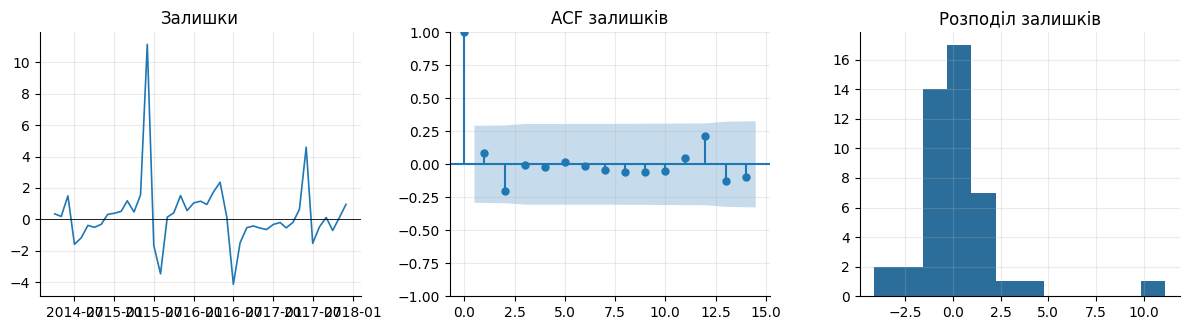

     lb_stat  lb_pvalue
6   2.406854   0.878743
12  6.240326   0.903486


In [19]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

def f_arima111(tr, h):
    return np.asarray(ARIMA(np.asarray(tr, float), order=(1, 1, 1)).fit().forecast(h))

Y_a, P_a, _ = rolling_origin(f_arima111)
m_arima = metrics(Y_a, P_a)
print('ARIMA(1,1,1), рухомий початок 7×3:', {k: round(v, 3) for k, v in m_arima.items()})
print('Найкращий базис за MAE (', BEST, '):', {k: round(v, 3) for k, v in tab6.loc[BEST].items()})
for met in ['MAE', 'RMSE', 'MAPE, %']:
    d = (m_arima[met] / tab6.loc[BEST, met] - 1) * 100
    print(f'  {met:<8s} ARIMA {"гірша" if d > 0 else "краща"} за найкращий базис на {abs(d):.1f} %')
VERDICT_ARIMA_WINS = m_arima['MAE'] < tab6.loc[BEST, 'MAE']
print('\n→ ARIMA(1,1,1) перевершує базис за MAE:', VERDICT_ARIMA_WINS)

# залишки моделі, навченої на всьому ряді
fit = ARIMA(y, order=(1, 1, 1)).fit(); print(fit.summary().tables[1])
res_ = pd.Series(fit.resid[1:], index=series.index[1:])
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
axes[0].plot(res_.index, res_.values, lw=1.2); axes[0].axhline(0, color='k', lw=.6); axes[0].set_title('Залишки')
plot_acf(res_, lags=14, ax=axes[1], title='ACF залишків'); axes[2].hist(res_, bins=12, color='#2C6E9B'); axes[2].set_title('Розподіл залишків')
plt.tight_layout(); plt.show()
print(acorr_ljungbox(res_, lags=[6, 12]))

**Висновок до завдання 7:**

ARIMA(1,1,1) гірша за просте середнє за всіма метриками, а за точністю близька до наївного прогнозу. Коефіцієнт MA майже дорівнює −1 і оцінений ненадійно: диференціювання тут зайве, і модель фактично зводиться до AR(1) на рівнях. За ACF/PACF і тестами я б обрала ARIMA(1,0,0). У залишках немає автокореляції, але є великі викиди в місяці піків, тобто модель не передбачає різких стрибків. Практичної цінності для цього ряду вона не має.

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

Знайдена дата: 03.2015;  t = -5.60;  середнє до = 3.32,  після = 6.48
p (Велч, наївно) = 1.3e-06;  після поправки Бонферроні на 35 кандидатів: p = 4.6e-05


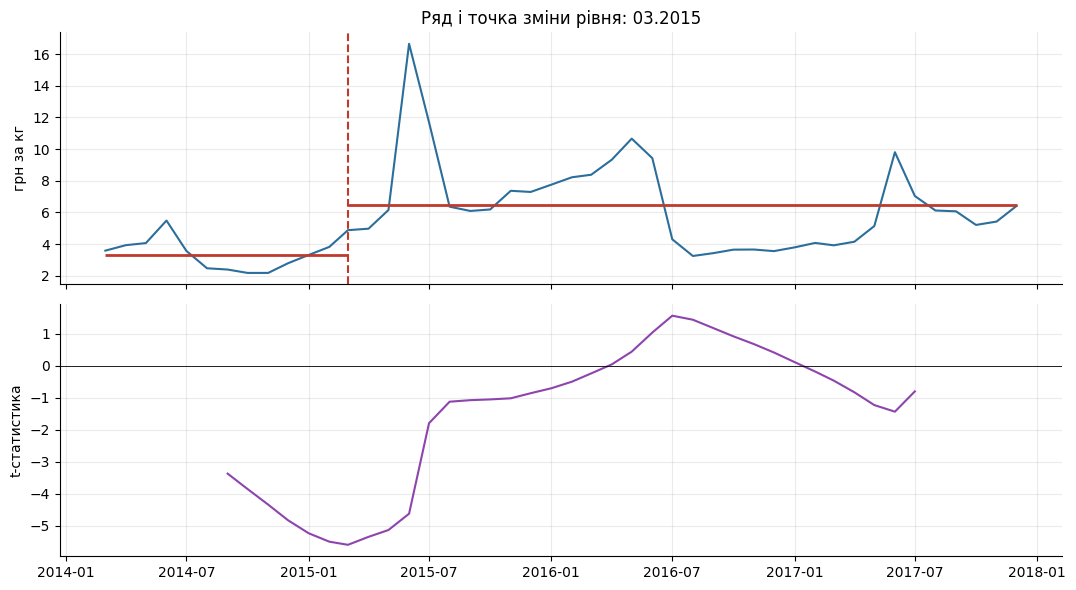

2014-03–2015-02: середнє 3.32, медіана 3.44
2015-03–2016-06: середнє 8.21, медіана 7.56
2016-07–2017-12: середнє 4.94, медіана 4.23

Пік (мах) кожного року та його місяць:
date
2014    06
2015    06
2016    05
2017    06
Name: price, dtype: str


In [10]:
MIN_SEG = 6                     # мінімум 6 місяців з кожного боку
cands = range(MIN_SEG, N - MIN_SEG + 1)
scan = []
for k in cands:
    a, b = y[:k], y[k:]
    t = stats.ttest_ind(a, b, equal_var=False)
    scan.append((series.index[k], t.statistic, t.pvalue, a.mean(), b.mean()))
scan = pd.DataFrame(scan, columns=['date', 't', 'p', 'mean_before', 'mean_after']).set_index('date')
cp = scan['t'].abs().idxmax(); r = scan.loc[cp]
n_c = len(scan); p_bonf = min(1, r['p'] * n_c)
print(f'Знайдена дата: {cp:%m.%Y};  t = {r["t"]:.2f};  середнє до = {r["mean_before"]:.2f},  після = {r["mean_after"]:.2f}')
print(f'p (Велч, наївно) = {r["p"]:.2g};  після поправки Бонферроні на {n_c} кандидатів: p = {p_bonf:.2g}')

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(series.index, y, color='#2C6E9B', lw=1.5); axes[0].axvline(cp, color='#C0392B', ls='--', lw=1.5)
axes[0].hlines(r['mean_before'], series.index[0], cp, color='#C0392B', lw=2); axes[0].hlines(r['mean_after'], cp, series.index[-1], color='#C0392B', lw=2)
axes[0].set_ylabel('грн за кг'); axes[0].set_title(f'Ряд і точка зміни рівня: {cp:%m.%Y}')
axes[1].plot(scan.index, scan['t'], color='#8E44AD'); axes[1].axhline(0, color='k', lw=.6); axes[1].set_ylabel('t-статистика')
plt.tight_layout(); plt.show()

# чи повертається рівень? порівняємо три відрізки
for a, b in [('2014-03', '2015-02'), ('2015-03', '2016-06'), ('2016-07', '2017-12')]:
    print(f'{a}–{b}: середнє {series[a:b].mean():.2f}, медіана {series[a:b].median():.2f}')
print('\nПік (мах) кожного року та його місяць:'); print(series.groupby(series.index.year).idxmax().dt.strftime('%m'))

**Висновок до завдання 8:**

Метод знайшов найімовірнішу точку зміни рівня в **березні 2015 року**: до неї середня ціна близько 3,3 грн, після — близько 6,5 грн, тобто приблизно вдвічі вище.

**Чи значущий зсув.** Формально p-значення дуже мале, і навіть після поправки на кількість перевірених дат (Бонферроні) воно лишається малим. Але довіряти йому повністю не можна: тест припускає незалежні спостереження, а місячні ціни автокорельовані, до того ж дату обрано як найкращу з багатьох. Тому правильно казати, що зсув очевидний за величиною, а його статистична значущість завищена.

**Це зміна режиму чи сезонний пік.** Це не сезонний пік. Сезонний пік повторюється щороку в одні й ті самі місяці й швидко спадає, а тут підвищений рівень тримався понад рік (з березня 2015 до середини 2016). Проте це й не зміна режиму назавжди: з липня 2016 року ціна повернулась майже до рівня 2014 року. Отже, у ряді є тимчасове підвищення рівня, на яке накладаються щорічні літні піки.

**Можливе пояснення.** Березень 2015 збігається за часом із різкою девальвацією гривні, яка могла підняти ціни. Це лише припущення: у наборі даних курсу валюти немає, тож перевірити його неможливо.

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

In [21]:
# Перевіряю твердження з рецензованого зошита на його даних — Вінниччина, гречка
bw = lambda m, t: prices[(prices['ринок']==m)&(prices['товар']==t)].sort_values('date').set_index('date')['ціна']
sv, beef, lv = bw('Vinnytsia','Buckwheat grits - Retail'), bw('Vinnytsia','Meat (beef) - Retail'), bw('Lviv','Buckwheat grits - Retail')

print('1) Довжина ряду без reindex:', len(sv), '(очікується 46); пропуск:', [d.strftime('%m.%Y') for d in GRID.difference(sv.index)])
print(f'2) Березень 2014 = {sv.iloc[0]:.2f}, грудень 2017 = {sv.iloc[-1]:.2f}, відношення = {sv.iloc[-1]/sv.iloc[0]:.2f}; але максимум = {sv.max():.2f} ({sv.idxmax():%m.%Y}), '
      f'тобто кінцева точка вдвічі нижча за пік')
mae_ = lambda x: (x - x.shift()).abs().mean(); mape_ = lambda x: ((x - x.shift()).abs() / x).mean() * 100
print(f'3) MAE гречки = {mae_(sv):.2f}, яловичини = {mae_(beef):.2f}  |  відносно рівня: {mape_(sv):.1f} % проти {mape_(beef):.1f} %  (середній рівень {sv.mean():.0f} vs {beef.mean():.0f} грн)')
print(f'4) r (рівні) = {sv.corr(lv):.3f};  r (різниці) = {sv.diff().corr(lv.diff()):.3f}')
z = (sv - sv.mean()) / sv.std()
print(f'7) |z|>1.3: {int((z.abs()>1.3).sum())} місяців (з них у 2014 р.: {int((z[z.abs()>1.3].index.year==2014).sum())}); |z|>2: {int((z.abs()>2).sum())}')
d1, d2 = sv.diff().dropna(), sv.diff().diff().dropna()
print(f'6) ACF лаг 1: перша різниця = {d1.autocorr(1):.2f}, друга різниця = {d2.autocorr(1):.2f}')
w = sv['2016-01':'2016-06']; print(f'10) Січ–чер 2016: {w.iloc[0]:.2f} → {w.iloc[-1]:.2f} (+{(w.iloc[-1]/w.iloc[0]-1)*100:.0f} %); вісь Y обрізана на ≈ {w.min()*0.995:.1f}, а не на 0')

1) Довжина ряду без reindex: 45 (очікується 46); пропуск: ['08.2017']
2) Березень 2014 = 7.16, грудень 2017 = 17.67, відношення = 2.47; але максимум = 36.93 (07.2016), тобто кінцева точка вдвічі нижча за пік
3) MAE гречки = 1.38, яловичини = 1.51  |  відносно рівня: 6.2 % проти 1.9 %  (середній рівень 21 vs 78 грн)
4) r (рівні) = 0.996;  r (різниці) = 0.936
7) |z|>1.3: 12 місяців (з них у 2014 р.: 9); |z|>2: 0
6) ACF лаг 1: перша різниця = 0.43, друга різниця = -0.13
10) Січ–чер 2016: 24.89 → 34.99 (+41 %); вісь Y обрізана на ≈ 24.8, а не на 0


**Висновок до завдання 9: рецензія на ЛР4_помилковий_аналіз.ipynb**

*(номери — індекси клітинок рецензованого зошита)*

| № | Клітинка | Помилка | Наслідок |
|---|---|---|---|
| 1 | 1, 3 | Ряд не приведено до повної сітки, тому відсутній місяць (серпень 2017) не видно й зроблено висновок «пропусків немає». | Пропуск лишається прихованим, а місяці «з'їжджають». |
| 2 | 5 | Зростання оцінено за двома кінцевими точками в різні сезони; пік насправді був посередині ряду. Про «купівельну спроможність» даних немає. | Кінцеві точки приховують траєкторію, висновок безпідставний. |
| 3 | 7 | Порівнюються абсолютні похибки товарів із різним масштабом цін. Відносно рівня цін висновок виходить протилежним. | Метрика залежить від масштабу, висновок хибний. |
| 4 | 9 | Кореляція рівнів двох трендових рядів і висновок, що один ринок «визначає» інший. | Хибна кореляція та причинність без підстав. |
| 5 | 11 | Сезонність «доведено» самим фактом роботи STL, без $F_S$; далі використано несезонні моделі. | Сезонність не доведено, висновок суперечить коду. |
| 6 | 13 | Перевернуто сенс ADF (великий p прочитано як «стаціонарний»), потім зайве подвійне диференціювання, KPSS не застосовано. | Хибний висновок про стаціонарність, штучна залежність. |
| 7 | 15 | У тексті «два σ», у коді поріг менший; «аномалії» — це початок ряду з низьким рівнем, тобто тренд. | Тренд і сезон видано за події. |
| 8 | 17 | Випадковий поділ часового ряду, тестові значення відсортовано, а базис порахований не на тих самих точках. | Помилку занижено, «висока точність» не доведена. |
| 9 | 19 | Прогнозує модель (2,2,1), яку не перевіряли; сезонність проігноровано, інтервалів немає. | Прогноз нічим не підтверджений. |
| 10 | 21 | Стовпчикова діаграма з обрізаною віссю Y. | Зміну візуально перебільшено. |
| 11 | 22 | Підсумки повторюють хибні висновки вище (зростання в кілька разів, «стаціонарний», «придатна для прогнозу»). | Помилки накопичуються. |

**Три найсерйозніші помилки та виправлення:**

1. **Випадковий поділ і відсортовані тестові значення (№ 8).** Потрібна перевірка з рухомим початком, порівняння з фактом у тих самих датах і з наївними базисами.
2. **Хибне прочитання ADF та надмірне диференціювання (№ 6).** Читати ADF і KPSS разом, брати мінімальне $d$ і перевіряти ACF різниці.
3. **Прихований пропуск (№ 1).** Спершу `reindex` на повну сітку, потім обґрунтоване заповнення, і лише потім STL чи ARIMA.

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [22]:
out = pd.DataFrame({'date': series.index.strftime('%Y-%m-%d'), 'price': series.values.round(4)})
out.to_csv('ряд_для_orange.csv', index=False, encoding='utf-8')

chk = pd.read_csv('ряд_для_orange.csv')
print(chk.head(3).to_string(index=False)); print('...'); print(chk.tail(2).to_string(index=False))
assert list(chk.columns) == ['date', 'price']
assert len(chk) == 46, len(chk)
assert chk.isna().sum().sum() == 0
assert (chk['date'].str.match(r'^\d{4}-\d{2}-01$')).all()
assert pd.to_datetime(chk['date']).is_monotonic_increasing and chk['date'].is_unique
print('\nРядків даних:', len(chk), '| порожніх значень:', int(chk.isna().sum().sum()), '| роздільник — кома, UTF-8')
print('Заповнене значення, серпень 2017:', chk.loc[chk['date'] == '2017-08-01', 'price'].item())

      date  price
2014-03-01 3.5867
2014-04-01 3.9333
2014-05-01 4.0633
...
      date  price
2017-11-01 5.4233
2017-12-01 6.4100

Рядків даних: 46 | порожніх значень: 0 | роздільник — кома, UTF-8
Заповнене значення, серпень 2017: 6.1211


**Висновок до завдання 10:**

Файл `ряд_для_orange.csv` містить 46 рядків без порожніх значень, дати у форматі `РРРР-ММ-01`. Пропуск серпня 2017 уже заповнено, тож Python і Orange працюють з однаковим рядом.

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

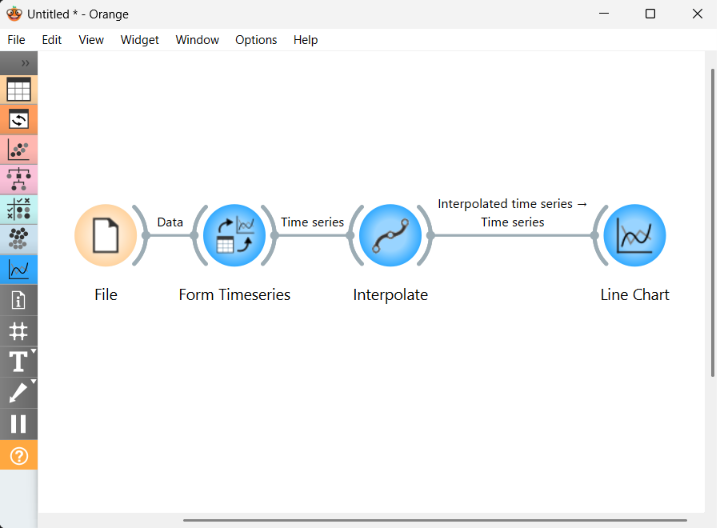

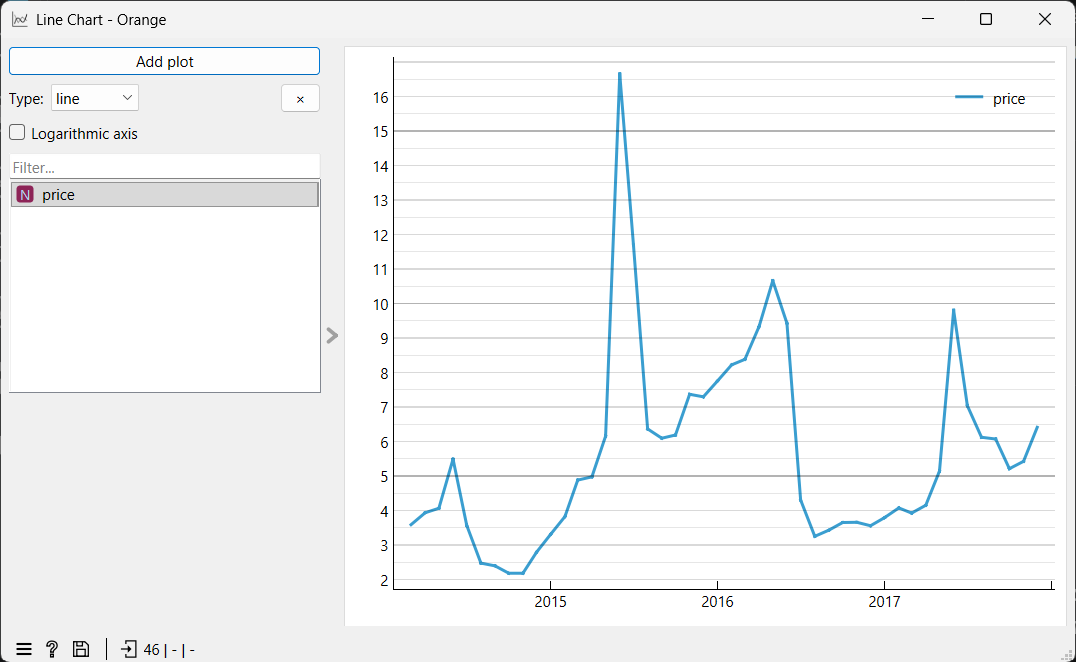

In [13]:
from IPython.display import Image, display
import os
for f in ['orange_потік.png', 'orange_line_chart.png']:
    display(Image(f)) if os.path.exists(f) else print(f'⚠️ Додайте знімок {f}')

**Висновок до завдання 11:**

У Orange побудовано потік File → Form Timeseries → Interpolate → Line Chart (у завданні цей віджет названо As Timeseries). Пропуск заповнено ще в Python, тому Interpolate нічого не змінює. Графік збігається з графіком із завдання 3, отже обидва середовища працюють з одними даними.

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

Межа значущості ≈ ± 0.289
                     0     1     2     3     4     5     6     7     8     9     10    11    12
ACF рівня           1.0  0.67  0.35  0.23  0.15  0.08  0.00 -0.07 -0.12 -0.14 -0.12 -0.08 -0.07
ACF першої різниці  1.0 -0.02 -0.30 -0.04 -0.05  0.01 -0.02 -0.03 -0.04 -0.05 -0.04  0.07  0.26


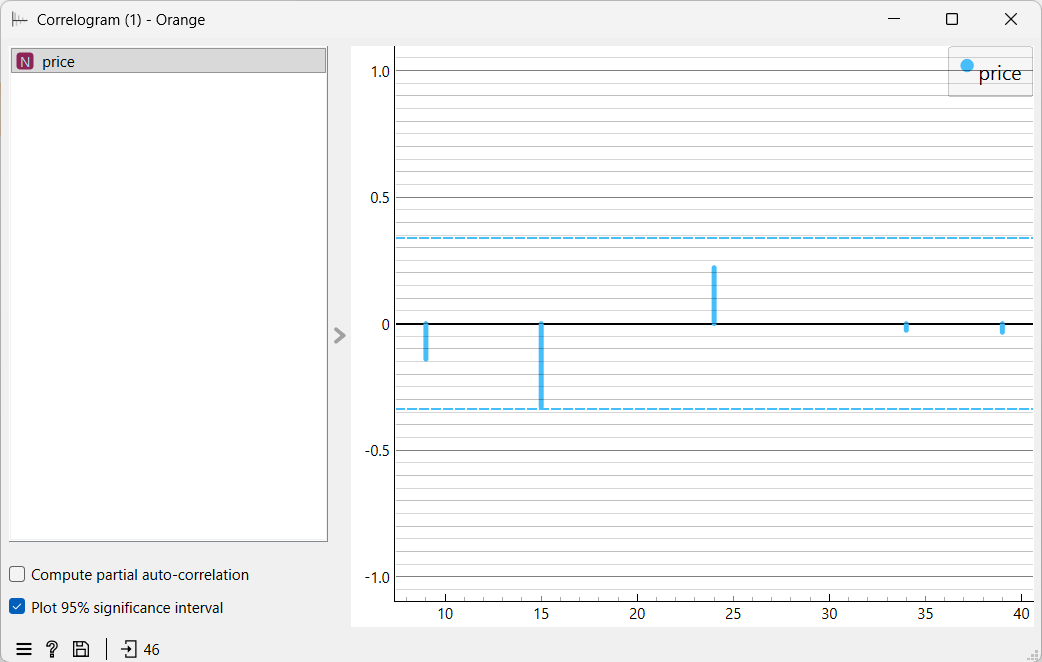

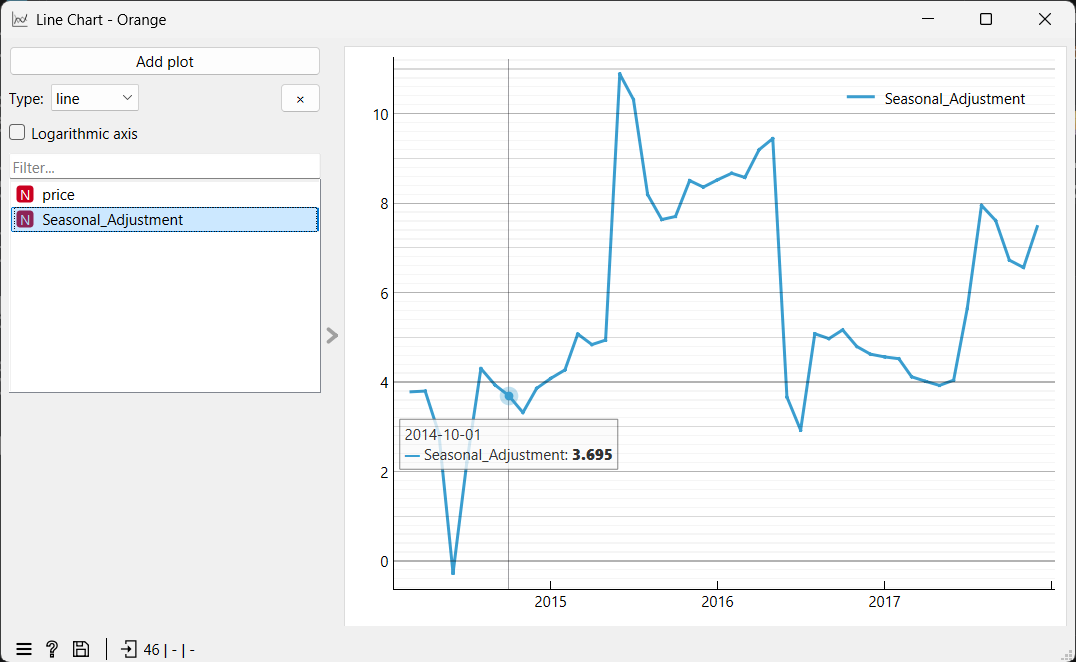

In [14]:
# Завдання 12 виконується в Orange (Correlogram, Difference, Seasonal Adjustment).
from statsmodels.tsa.stattools import acf as _acf
a_lvl = _acf(series.values, nlags=12, fft=False); a_dif = _acf(np.diff(series.values), nlags=12, fft=False)
print('Межа значущості ≈ ±', round(1.96 / np.sqrt(N), 3))
print(pd.DataFrame({'ACF рівня': a_lvl, 'ACF першої різниці': a_dif}).round(2).T.to_string())
from IPython.display import Image, display
import os
for f in ['orange_correlogram.png', 'orange_seasonal_adjustment.png']:
    display(Image(f)) if os.path.exists(f) else print(f'Додайте знімок {f}')

**Висновок до завдання 12:**

ACF вихідного ряду має значущі перші лаги й плавно спадає, тобто ряд інерційний, але стаціонарний. Перша різниця прибирає автокореляцію першого порядку, але дає від'ємну на лагу 2, що знову вказує на зайве диференціювання. Корелограма Orange на знімку показує лише частину лагів; видимий лаг 9 збігається з Python, а довірчу смугу Orange малює по-своєму. Seasonal Adjustment в Orange і STL бачать той самий літній пік, але різної величини: Orange щороку віднімає майже однакову суму, STL — меншу й змінну. Тому скоригований ряд Orange не позбувся піку 2015 року, а в 2014 році пішов нижче нуля. Це ще раз показує, що сезонність нестабільна.

## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

Ряд: 46 спостережень; K = 7, H = 3; тестових точок 21; найкоротша навчальна частина 25
 фолд        навчання  n_train            тест
    1 03.2014–03.2016       25 04.2016–06.2016
    2 03.2014–06.2016       28 07.2016–09.2016
    3 03.2014–09.2016       31 10.2016–12.2016
    4 03.2014–12.2016       34 01.2017–03.2017
    5 03.2014–03.2017       37 04.2017–06.2017
    6 03.2014–06.2017       40 07.2017–09.2017
    7 03.2014–09.2017       43 10.2017–12.2017

Типовий варіант: 20 фолдів × 3 кроки = 60 тестових точок > 46 точок усього ряду → навчальної частини лишилося б -14 (< 0): розбиття неможливе.
Максимум фолдів по 3 кроки без «порожнього» навчання: 15


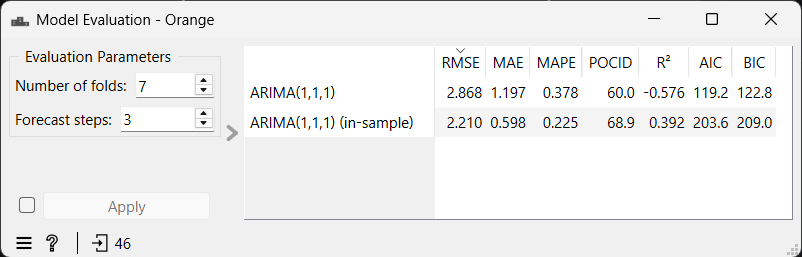

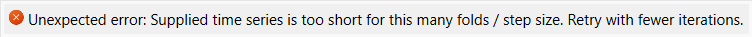

In [15]:
print(f'Ряд: {N} спостережень; K = {K}, H = {H}; тестових точок {K*H}; найкоротша навчальна частина {N - K*H}')
rows = [{'фолд': K - i + 1, 'навчання': f'{series.index[0]:%m.%Y}–{series.index[N-i*H-1]:%m.%Y}', 'n_train': N - i * H,
         'тест': f'{series.index[N-i*H]:%m.%Y}–{series.index[N-i*H+H-1]:%m.%Y}'} for i in range(K, 0, -1)]
print(pd.DataFrame(rows).to_string(index=False))
print(f'\nТиповий варіант: 20 фолдів × 3 кроки = {20*3} тестових точок > {N} точок усього ряду →',
      f'навчальної частини лишилося б {N - 20*3} (< 0): розбиття неможливе.')
print('Максимум фолдів по 3 кроки без «порожнього» навчання:', (N - 1) // 3)
from IPython.display import Image, display
import os
for f in ['orange_model_evaluation.png', 'orange_error_20folds.png']:
    display(Image(f)) if os.path.exists(f) else print(f'⚠️ Додайте знімок {f}')

**Висновок до завдання 13:**

Orange оцінив ARIMA(1,1,1) на 7 фолдах по 3 кроки. На тестових даних модель гірша за просте середнє (R² від'ємний), а на навчальних виглядає значно краще. При 20 фолдах × 3 кроки Orange видає помилку «too short for this many folds / step size»: потрібно 60 тестових точок, а в ряді лише 46. У схемі з 7 фолдів навчальна частина розширюється від 25 до 43 місяців, а збіг RMSE з Python підтверджує, що фолди в обох середовищах однакові.

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [16]:
# Завдання 14. Відтворення метрик Orange.
# Значення з вікна Model Evaluation (ARIMA(1,1,1), folds = 7, steps = 3, out-of-sample):
ORANGE = {'RMSE': 2.868, 'MAE': 1.197, 'MAPE': 0.378, 'R2': -0.576, 'POCID': 60.0}

Y_o, P_o = Y_a, P_a                       # 21 об'єднаний прогноз ARIMA(1,1,1) із завдання 7
e = Y_o - P_o
last_train = y[N - K * H - 1]             # останнє відоме значення перед першим тестовим місяцем
sse, sst = np.sum(e ** 2), np.sum((Y_o - Y_o.mean()) ** 2)
by_fold = lambda f: np.array([f(e[i*H:(i+1)*H]) for i in range(K)])
hit = lambda prev, act, pred: 100 * np.mean((act > prev) == (pred > prev))
A = 100 * np.mean(np.diff(Y_o) * np.diff(P_o) > 0)

CAND = {
  'RMSE':  {'√(Σe²/21), усі 21 точка разом':       np.sqrt(np.mean(e ** 2)),
            'середнє RMSE по 7 фолдах':            by_fold(lambda x: np.sqrt(np.mean(x ** 2))).mean()},
  'MAE':   {'середнє |e|':                         np.mean(np.abs(e)),
            'медіана |e|':                         np.median(np.abs(e)),
            'медіана з MAE по фолдах':             np.median(by_fold(lambda x: np.mean(np.abs(x))))},
  'MAPE':  {'середнє |e|/y (частка)':              np.mean(np.abs(e) / Y_o),
            'Σ|e| / Σ|y| (частка)':                np.sum(np.abs(e)) / np.sum(np.abs(Y_o)),
            'медіана |e|/y (частка)':              np.median(np.abs(e) / Y_o)},
  'R2':    {'1 − SSE/SST, 21 точка разом':         1 - sse / sst},
  'POCID': {'A: знак Δy проти знака Δŷ (20 пар)':  A,
            'B: ŷ_t проти y_{t−1}, 21 пара':       hit(np.r_[last_train, Y_o[:-1]], Y_o, P_o),
            'C: ŷ_t проти y_{t−1}, 20 пар':        hit(Y_o[:-1], Y_o[1:], P_o[1:]),
            'D: 100 − A (частка НЕзбігів знаків)': 100 - A},
}
TOL = {'RMSE': .0006, 'MAE': .0006, 'MAPE': .0006, 'R2': .0006, 'POCID': .06}
FOUND = {}
for m_, cands in CAND.items():
    print(f'\n{m_:<6s} Orange = {ORANGE[m_]}')
    for name, v in cands.items():
        ok = abs(v - ORANGE[m_]) <= TOL[m_]
        print(f'   {"✔" if ok else " "} {name:<40s} {v:10.4f}')
        if ok: FOUND.setdefault(m_, []).append(name)

print('\nФормула, що відтворює число Orange:')
for m_ in ORANGE: print(f'   {m_:<6s}', FOUND.get(m_, '— жодний кандидат не збігся: перегляньте functions.py'))
POCID_KIND = FOUND['POCID'][0][0] if 'POCID' in FOUND else 'C'     # потрібно для завдання 15

# Автоперевірка з оригіналом, якщо встановлено Orange3-Timeseries
try:
    from orangecontrib.timeseries import functions as F
    for n_ in ['rmse', 'mae', 'mape', 'pocid', 'r2']:
        if hasattr(F, n_): print('functions.%s ->' % n_, getattr(F, n_)(Y_o, P_o))
except Exception as ex:
    print('\n(Orange3-Timeseries у цьому Python не встановлено — звірку з functions.py виконано за числами з Orange)')


RMSE   Orange = 2.868
   ✔ √(Σe²/21), усі 21 точка разом                2.8677
     середнє RMSE по 7 фолдах                     2.3149

MAE    Orange = 1.197
     середнє |e|                                  2.1329
   ✔ медіана |e|                                  1.1966
     медіана з MAE по фолдах                      1.9179

MAPE   Orange = 0.378
     середнє |e|/y (частка)                       0.4208
   ✔ Σ|e| / Σ|y| (частка)                         0.3783
     медіана |e|/y (частка)                       0.1937

R2     Orange = -0.576
   ✔ 1 − SSE/SST, 21 точка разом                 -0.5761

POCID  Orange = 60.0
     A: знак Δy проти знака Δŷ (20 пар)          40.0000
     B: ŷ_t проти y_{t−1}, 21 пара               57.1429
   ✔ C: ŷ_t проти y_{t−1}, 20 пар                60.0000
   ✔ D: 100 − A (частка НЕзбігів знаків)         60.0000

Формула, що відтворює число Orange:
   RMSE   ['√(Σe²/21), усі 21 точка разом']
   MAE    ['медіана |e|']
   MAPE   ['Σ|e| / Σ|y| (частка)']
  

**Висновок до завдання 14:**

| Метрика | Orange | Що насправді рахується |
|---|---|---|
| RMSE | 2,868 | Корінь із середнього квадрата похибок — збігається одразу |
| R² | −0,576 | $1 - \mathrm{SSE}/\mathrm{SST}$ — збігається |
| MAPE | 0,378 | Відношення сум $\sum\lvert e\rvert / \sum\lvert y\rvert$, у частках |
| MAE | 1,197 | Медіана абсолютних похибок |
| POCID | 60,0 | Чи правильно прогноз вгадав напрямок відносно попереднього фактичного значення |

Назві не відповідають MAE (це медіана, а не середнє) і MAPE (відношення сум, а не середнє відсоткових похибок). Одразу збігся RMSE, і саме він доводить, що дані, фолди й прогнози в обох середовищах однакові. Отже, розбіжність створюють різні означення метрик, а не різні моделі. Перш ніж порівнювати числа двох інструментів, треба перевірити дані, фолди, спосіб усереднення, одиниці та точну формулу.

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [17]:
# Матриця напрямку зміни — за тим означенням POCID, яке збіглося з Orange у завданні 14 (POCID_KIND)
if POCID_KIND in ('A', 'D'):
    act_up, pred_up = np.diff(Y_o) > 0, np.diff(P_o) > 0
elif POCID_KIND == 'B':
    prev = np.r_[last_train, Y_o[:-1]]; act_up, pred_up = Y_o > prev, P_o > prev
else:
    prev = Y_o[:-1]; act_up, pred_up = Y_o[1:] > prev, P_o[1:] > prev

lab = {True: 'зросла', False: 'впала / без змін'}
cm = pd.crosstab(pd.Series(act_up).map(lab).rename('факт'), pd.Series(pred_up).map(lab).rename('прогноз моделі'))
cm = cm.reindex(index=list(lab.values()), columns=list(lab.values()), fill_value=0)
print(cm)

n_ = len(act_up); k_ = int((act_up == pred_up).sum())
acc = 100 * k_ / n_
print(f'\nВірно вгадано напрямок: {k_} з {n_} = {acc:.1f} %   |   POCID у Orange: {ORANGE["POCID"]} %')
if POCID_KIND == 'D': print('Увага: у Orange число = частка НЕзбігів знаків (100 − A); діагональ матриці дає 100 − POCID.')
base = max(act_up.mean(), 1 - act_up.mean()) * 100
print(f'Тривіальна стратегія «завжди кажи: {"зросте" if act_up.mean() >= .5 else "впаде"}»: {int(round(base * n_ / 100))} з {n_} = {base:.1f} %')
print('Чутливість (з фактичних зростань знайдено):', round(100 * cm.iloc[0, 0] / max(cm.iloc[0].sum(), 1), 1), '%;',
      ' специфічність (з фактичних падінь знайдено):', round(100 * cm.iloc[1, 1] / max(cm.iloc[1].sum(), 1), 1), '%')

прогноз моделі    зросла  впала / без змін
факт                                      
зросла                 9                 2
впала / без змін       6                 3

Вірно вгадано напрямок: 12 з 20 = 60.0 %   |   POCID у Orange: 60.0 %
Тривіальна стратегія «завжди кажи: зросте»: 11 з 20 = 55.0 %
Чутливість (з фактичних зростань знайдено): 81.8 %;  специфічність (з фактичних падінь знайдено): 33.3 %


**Висновок до завдання 15:**

Модель правильно вгадала напрямок у 12 випадках із 20 (60 %), що збігається з POCID в Orange. Проте стратегія «завжди кажи: зросте» дала б 11 з 20, тож перевага мінімальна. Матриця показує, що модель здебільшого передбачає зростання: більшість зростань вона знаходить, але падіння майже не розпізнає. Для рішення «купувати зараз чи чекати» важливий саме напрямок, а не величина похибки (MAE, RMSE), але тут модель практичної користі не дає.

---
# Загальний висновок

1. Сильної сезонності в ряді немає: літній пік повторюється щороку, але його висота дуже нестабільна.
2. Найкращим виявився не ARIMA, а найпростіший базис — середнє. ARIMA(1,1,1) йому програє, а її параметри показують, що диференціювання зайве.
3. Є зсув рівня в березні 2015 року, але він тимчасовий: згодом ціна повернулась майже до рівня 2014 року. Зв'язок із девальвацією — лише гіпотеза.
4. Метрики в Python і Orange різняться через означення, а не через дані: RMSE і R² збіглися, а MAE (медіана), MAPE (відношення сум) і POCID в Orange рахуються інакше.
5. Через малу довжину ряду (46 спостережень) надійно оцінити стійкість сезонності, потужність тестів і різницю між кандидатними моделями неможливо.

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | Claude (Anthropic) |
| Для яких саме завдань | Завдання 1–10 (код і висновки Частини 1, у т.ч. рецензія на помилковий зошит); завдання 11–15 — виправлення й формулювання письмових висновків за моїми виводами та знімками (сам потік Orange і знімки зроблено мною) |
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | Код усіх клітинок Частини 1 та клітинок відтворення метрик Orange (завдання 14–15); тексти висновків; перелік помилок рецензованого зошита; пояснення формул метрик Orange (MAPE як Σ\|e\|/Σ\|y\| у частках тощо); виправлення висновків після мого запуску зошита |
| Що ви змінили у згенерованому результаті й чому | Запустила зошит локально (Python 3.13, statsmodels 0.15.0) і замінила попередні оцінки ШІ фактичними числами з виводу: F_S = 0,372 (а не ≈ 0,65), ARIMA(1,1,1) — MAE 2,133 / RMSE 2,868 / MAPE 42,1 %; виправила текст помилки Orange за 20 фолдів на дослівний зі знімка та опис віджета Interpolate; у завданні 12 уточнила порівняння корелограми й сезонного коригування за власними знімками Orange |
| Що ви **перевірили самостійно** і яким способом | Повний запуск зошита; побудова потоку в Orange (File → Form Timeseries → Interpolate → ARIMA Model / Model Evaluation / Correlogram / Difference / Line Chart); зіставлення таблиці Model Evaluation з Python: RMSE (2,868) і R² (−0,576) збіглися до третього знака, MAPE пояснено відношенням сум 44,8 / 118,4 = 0,378; збіг лагу 9 корелограми Orange (≈ −0,14) з ACF із Python; графік Line Chart порівняно з графіком 1 із завдання 3 |
| Чи траплялися у відповідях ШІ помилки; якщо так — які | Так. (1) Перша версія тексту вказувала F_S ≈ 0,65 — фактично 0,372, тож сильної сезонності немає. (2) Стверджувалося, що в залишках ARIMA лишилась структура, — тест Льюнга–Бокса (p = 0,88 і 0,90) цього не підтвердив. (3) MAPE ARIMA названо «на рівні базису» — насправді на 10 % гірша. (4) Спочатку невірно описано роботу Interpolate (пропуск заповнено ще в Python) і наведено інший текст помилки Orange. (5) Не вдалося наперед визначити формули MAE та POCID в Orange — їх встановлено перебором кандидатів у коді завдання 14. Усе виправлено за фактичними виводами |

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

> Підпис: ___Khvostova___  Дата: 28.10.2026